# Part 1: CNN MIL

Attach the soil competition data and the soil-cv-utils code dataset, version 6.
Use Internet, 2 x T4 GPUs, and the WANDB_API_KEY secret. Then Save & Run All.
All code is in the dataset. Outputs stay on Kaggle. No CV-summary runs are made.
The old tile-loss study stays in earlier notebook versions.

In [1]:
from pathlib import Path
import os
import sys
import json
import subprocess

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['TORCH_HOME'] = '/tmp/soilcv-torch'
os.environ['WANDB_CACHE_DIR'] = '/tmp/soilcv-wandb-cache'
code_root = Path('/kaggle/input/datasets/denysmykhailov/soil-cv-utils')
if not (code_root/'soilcv/bags.py').is_file():
    paths = list(Path('/kaggle/input').rglob('soilcv/bags.py'))
    if len(paths) != 1:
        raise RuntimeError('Attach the latest code dataset with soilcv/bags.py.')
    code_root = paths[0].parents[1]
sys.path.insert(0,str(code_root))
os.environ['PYTHONPATH'] = str(code_root) + os.pathsep + os.environ.get('PYTHONPATH','')
from kaggle_secrets import UserSecretsClient
os.environ['WANDB_API_KEY'] = UserSecretsClient().get_secret('WANDB_API_KEY')

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from soilcv.artifacts import package_identity
if package_identity()['source_hash'] != '431a69bd03d926c50897eac4f358c2b14b0b7366ace8b9b0ab3ffaa5b6f83008':
    raise RuntimeError('Select the MIL code dataset version for this notebook.')
from soilcv.cnn.experiments import ROOT,RECIPES,prepare
from soilcv.cnn.analysis import collect_results,plot_coverage,plot_scores,plot_learning
from soilcv.cnn.outputs import save_source,export_outputs
if torch.cuda.device_count() != 2:
    raise RuntimeError('Select two T4 GPUs.')
print('GPUs:',[torch.cuda.get_device_name(i) for i in range(2)])
print('Output folder:',ROOT)

GPUs: ['Tesla T4', 'Tesla T4']
Output folder: /kaggle/working/part1_mil


## Data and full coverage

One bag has all photos of one soil sample. It has all grid tiles. No tiles are sampled out.
All native pixels must be inside a tile. Edge tiles can overlap; area weights correct this.
Resizing can still lose small details. Full coverage is not proof of perfect physical scale.
224 and 288 use the same native rectangles and the same LANCZOS method, with one resize each.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /tmp/soilcv-torch/hub/checkpoints/resnet18-f37072fd.pth
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /tmp/soilcv-torch/hub/checkpoints/convnext_tiny-983f1562.pth
Run: 20261031T222435Z-d834b6698f | photos: 162 | tiles per resolution: 3646
Run ID: 20261031T222435Z-d834b6698f
Code: {'version': '0.1.1', 'source_hash': '431a69bd03d926c50897eac4f358c2b14b0b7366ace8b9b0ab3ffaa5b6f83008', 'folds_hash': '057fe8f93ba35d2ab7a3483063c95ca0079c4bcbb9978671c16ffc4119d9c1b2'}
224 px: 162 photos; missing native pixels: 0
288 px: 162 photos; missing native pixels: 0


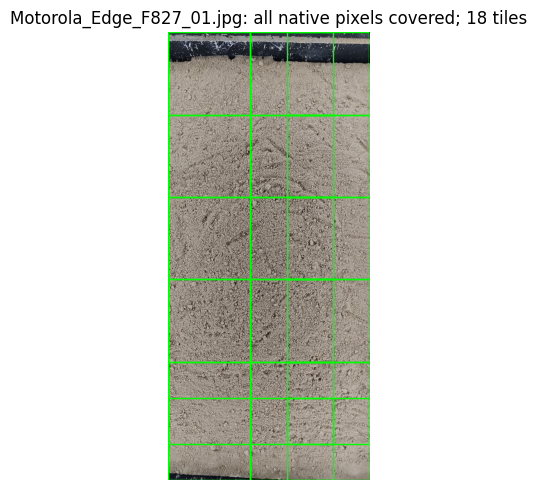

In [2]:
metadata = prepare()
save_source()
print('Run ID:',metadata['run_id'])
print('Code:',metadata['identity']['soilcv'])
for pixels in [224,288]:
    coverage = pd.read_csv(ROOT/f'coverage_{pixels}.csv')
    assert coverage.coverage.eq(1).all()
    assert coverage.missing_native_pixels.eq(0).all()
    print(pixels,'px:',len(coverage),'photos; missing native pixels:',coverage.missing_native_pixels.sum())
fig = plot_coverage()
fig.savefig(ROOT/'coverage_example.png',dpi=150)
plt.show()

## Planned MIL experiments

The CNN reads tiles in small chunks. It pools features within photos, then across photos.
One curve head and one EMD loss are used for the whole sample.
Encoder checkpointing keeps the full bag but uses less GPU memory.
Two complete sample losses make one optimizer update. BN statistics stay frozen.

The same four sample folds are used. We keep best-epoch selection for now.
A TODO in the code records the later checks with EMA, fixed epochs and more splits.

In [3]:
display(pd.DataFrame(RECIPES)[['id','arch','frozen','pixels','schedule','epochs','patience','accumulation_steps']])
print('Hypotheses commit:',metadata['identity']['hypotheses_commit'])
print((code_root/'HYPOTHESES.md').read_text())

,id,arch,frozen,pixels,schedule,epochs,patience,accumulation_steps
0,mil-r18-frozen-288,resnet18,True,288,constant,16,5,2
1,mil-r18-288,resnet18,False,288,constant,16,5,2
2,mil-r18-224,resnet18,False,224,constant,16,5,2
3,mil-r18-cosine,resnet18,False,288,warmup_cosine,16,5,2
4,mil-convnext-288,convnext_tiny,False,288,constant,16,5,2


Hypotheses commit: 0af70f4
# Hypotheses before the MIL run

The old tile-loss study is a reference. Its notebooks, results and checkpoints stay in the earlier Kaggle notebook versions and code dataset version 3. Local history is in archive/CNN_TILE_HISTORY.md. Its scores are not scores of the new MIL run.

Use the same four sample folds. Every photo of a sample stays in one fold.
One training item is one complete soil sample. Use all grid tiles of all its photos in train, validation and test. Do not randomly drop tiles or photos.

Use 64 mm crops and a full-image grid. Edge tiles overlap when needed. Check the union of rectangles for every photo. Use overlap-corrected area weights within each photo, then equal photo weights within each sample. Pool CNN features before the curve head. Compute EMD once per sample.

Each resolution gets its own cache directly from the same native rectangles with LANCZOS. There is no second resize. 224 and 288 use the same photos, bag weights, updates, fol

## Train and predict

Each GPU runs one fold. This cell waits until every job ends.
Each fold also predicts the test set on GPU and saves checkpoints.
A small reload check must reproduce one saved test curve. It is part of the real fold, not an extra W&B run.
Failed jobs stop the notebook and keep their logs. There is no online smoke run.

In [4]:
subprocess.run([sys.executable,'-m','soilcv.cnn.launcher'],check=True)
status = json.loads((ROOT/'status.json').read_text())
assert len(status['jobs']) == 4*len(RECIPES)
assert all(job['state']=='complete' for job in status['jobs'])
print('Complete folds:',len(status['jobs']))

started mil-r18-frozen-288 0 GPU 0
started mil-r18-frozen-288 1 GPU 1
complete mil-r18-frozen-288 0
started mil-r18-frozen-288 2 GPU 0
complete mil-r18-frozen-288 1
started mil-r18-frozen-288 3 GPU 1
complete mil-r18-frozen-288 2
started mil-r18-288 0 GPU 0
complete mil-r18-frozen-288 3
started mil-r18-288 1 GPU 1
complete mil-r18-288 0
started mil-r18-288 2 GPU 0
complete mil-r18-288 1
started mil-r18-288 3 GPU 1
complete mil-r18-288 2
started mil-r18-224 0 GPU 0
complete mil-r18-288 3
started mil-r18-224 1 GPU 1
complete mil-r18-224 0
started mil-r18-224 2 GPU 0
complete mil-r18-224 1
started mil-r18-224 3 GPU 1
complete mil-r18-224 2
started mil-r18-cosine 0 GPU 0
complete mil-r18-224 3
started mil-r18-cosine 1 GPU 1
complete mil-r18-cosine 0
started mil-r18-cosine 2 GPU 0
complete mil-r18-cosine 1
started mil-r18-cosine 3 GPU 1
complete mil-r18-cosine 2
started mil-convnext-288 0 GPU 0
complete mil-r18-cosine 3
started mil-convnext-288 1 GPU 1
complete mil-convnext-288 0
started mi

## Results for this run

These numbers come only from the current run ID. HYPOTHESES.md has no result table.
The old tile results are a reference. This new study changes both coverage and the loss.
It is not a clean loss-only comparison. Small CV gaps can be noise.

,experiment,run_id,arch,pixels,frozen,schedule,cv_emd,fold_std,gpu_hours,peak_gpu_mb,epochs_per_fold,public_lb,private_lb
0,mil-r18-cosine,20261031T222435Z-d834b6698f,resnet18,288,False,warmup_cosine,26.157,9.500,0.842,646.544,"13,16,15,16",not submitted,not available
1,mil-r18-288,20261031T222435Z-d834b6698f,resnet18,288,False,constant,30.977,16.554,0.706,646.544,"12,16,11,9",not submitted,not available
2,mil-convnext-288,20261031T222435Z-d834b6698f,convnext_tiny,288,False,constant,32.825,20.826,0.926,1601.238,"9,12,15,8",not submitted,not available
3,mil-r18-224,20261031T222435Z-d834b6698f,resnet18,224,False,constant,34.182,16.168,0.450,507.888,"15,11,9,16",not submitted,not available
4,mil-r18-frozen-288,20261031T222435Z-d834b6698f,resnet18,288,True,constant,37.783,15.439,0.457,467.778,"6,10,10,9",not submitted,not available


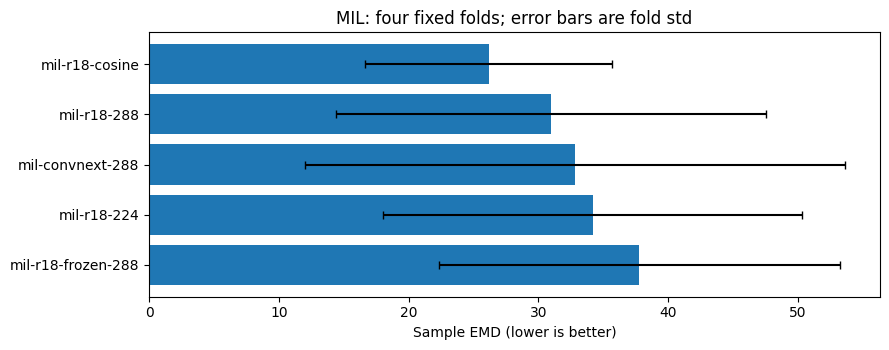

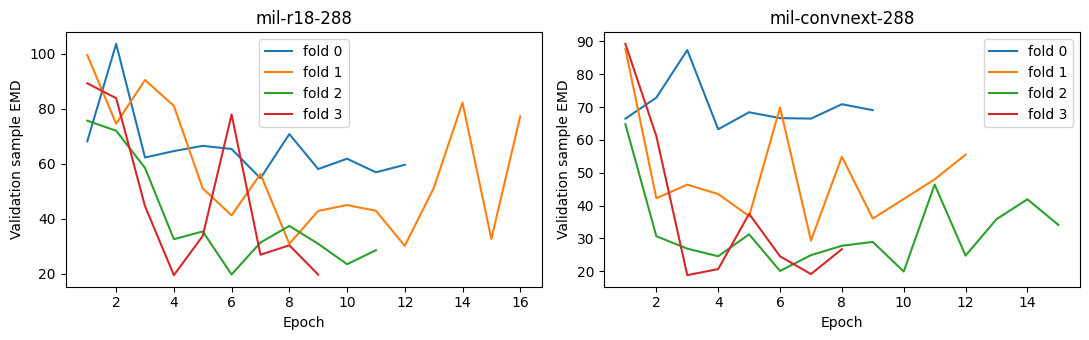

# CNN MIL results

Run ID: `20261031T222435Z-d834b6698f`.
Code hash: `431a69bd03d926c50897eac4f358c2b14b0b7366ace8b9b0ab3ffaa5b6f83008`.
Hypotheses commit: `0af70f4`.
Exact data and grid hashes are in metadata.json. Numbers below come from results/cnn_results.csv.

Best OOF EMD: 26.157. Fold standard deviation: 9.500. Recipe: mil-r18-cosine.

| Recipe | EMD | Fold std | Fit GPU-hours | Peak MB |
| --- | ---: | ---: | ---: | ---: |
| mil-r18-cosine | 26.157 | 9.500 | 0.842 | 647 |
| mil-r18-288 | 30.977 | 16.554 | 0.706 | 647 |
| mil-convnext-288 | 32.825 | 20.826 | 0.926 | 1601 |
| mil-r18-224 | 34.182 | 16.168 | 0.450 | 508 |
| mil-r18-frozen-288 | 37.783 | 15.439 | 0.457 | 468 |

## What happened

Frozen encoder: 37.783; tuned ResNet: 30.977.
Direct 224 px: 34.182; direct 288 px: 30.977.
Constant LR: 30.977; warmup/cosine: 26.157.
ConvNeXt: 32.825. More capacity does not promise a better score.
See paired_sample_errors.csv for changes on each of the same 24 samples. Small score gaps 

In [5]:
results,predictions,cameras = collect_results()
display(results.round(3))
fig = plot_scores(results)
fig.savefig(ROOT/'results/mil_scores.png',dpi=150)
plt.show()
fig = plot_learning()
fig.savefig(ROOT/'results/mil_learning.png',dpi=150)
plt.show()
print((ROOT/'CNN_RESULTS.md').read_text())

## Paired camera check

For the same held-out soil, compare Motorola and Samsung curves.
We report each camera's label error and their prediction disagreement.
All photo features are reused; no extra model is trained.
Camera and view both change. This does not prove transfer to iPhone.

In [6]:
display(cameras.round(3))
pairs = pd.read_csv(ROOT/'results/camera_pairs.csv')
display(pairs.sort_values('camera_disagreement',ascending=False).head(10))
print('Paired per-sample model errors:',ROOT/'results/paired_sample_errors.csv')
checks = []
for recipe in RECIPES:
    for fold in range(4):
        check = json.loads((ROOT/'runs'/recipe['id']/f'fold_{fold}'/'inference_check.json').read_text())
        checks.append({'experiment':recipe['id'],'fold':fold,**check})
display(pd.DataFrame(checks))

,experiment,paired_samples,motorola_emd,samsung_emd,camera_disagreement
0,mil-convnext-288,21,33.343,37.668,9.869
1,mil-r18-224,21,35.910,36.340,7.977
2,mil-r18-288,21,34.573,33.655,11.714
3,mil-r18-cosine,21,28.369,36.216,25.132
4,mil-r18-frozen-288,21,39.818,41.615,8.616


,experiment,sample_id,fold,motorola_emd,samsung_emd,camera_disagreement
82,mil-r18-cosine,H666,3,18.452664,108.538383,118.814082
81,mil-r18-cosine,H617,3,30.604891,45.388427,64.418805
66,mil-r18-cosine,H037,0,44.956379,15.657118,54.316873
83,mil-r18-cosine,H668,3,28.914950,69.079474,51.118149
63,mil-r18-cosine,F827,0,31.684684,73.361996,41.677312
14,mil-convnext-288,H516,0,26.033441,51.107607,37.656762
45,mil-r18-288,H037,0,93.082616,59.056474,34.180444
64,mil-r18-cosine,G190,0,24.682523,11.588039,33.310416
46,mil-r18-288,H038,0,130.975473,100.139454,30.836019
67,mil-r18-cosine,H038,0,77.011575,47.410338,29.601237


Paired per-sample model errors: /kaggle/working/part1_mil/results/paired_sample_errors.csv


,experiment,fold,sample_id,max_absolute_difference,tolerance,amp
0,mil-r18-frozen-288,0,HPC_Airbus BS10-4bis7,0.0,0.001,True
1,mil-r18-frozen-288,1,HPC_Airbus BS10-4bis7,0.0,0.001,True
2,mil-r18-frozen-288,2,HPC_Airbus BS10-4bis7,0.0,0.001,True
3,mil-r18-frozen-288,3,HPC_Airbus BS10-4bis7,0.0,0.001,True
4,mil-r18-288,0,HPC_Airbus BS10-4bis7,0.0,0.001,True
5,mil-r18-288,1,HPC_Airbus BS10-4bis7,0.0,0.001,True
6,mil-r18-288,2,HPC_Airbus BS10-4bis7,0.0,0.001,True
7,mil-r18-288,3,HPC_Airbus BS10-4bis7,0.0,0.001,True
8,mil-r18-224,0,HPC_Airbus BS10-4bis7,0.0,0.001,True
9,mil-r18-224,1,HPC_Airbus BS10-4bis7,0.0,0.001,True


## Kaggle Outputs

The full study is saved in part1_mil. It has weights, best/last checkpoints, curves,
coverage checks, camera results, configs, logs, hypotheses, source, and environment files.
CNN_RESULTS.md and results/cnn_results.csv identify this run.
submission.csv is also at the top level. No competition submission is sent.
The score uses only 24 samples and one split. Fold std is not a confidence interval.

In [7]:
from soilcv.curves import make_submission
submission = pd.read_csv(ROOT/'results/cnn_submission.csv')
make_submission(submission,pd.read_json(ROOT/'template.json'))
folder = export_outputs()
display(submission.head())
print('Submission shape:',submission.shape)
print('Full Outputs:',folder)
print('Submission:',ROOT.parent/'submission.csv')
print('W&B: https://wandb.ai/public-team/soil-grain-size')

Saved 364 study files in /kaggle/working/part1_mil


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,4.793741,9.748503,22.916437,50.873019,84.198960,93.398224,95.686032,97.631670,99.277563,99.972307,100.0
1,HPC_Audorfring,2.232098,4.895959,11.743933,25.729297,43.355386,55.421017,65.392772,78.132563,94.499982,99.906847,100.0
2,HPC_Muenster_BS6_9_0-10m,1.075413,2.347653,5.364449,10.809180,17.469261,25.841090,38.206643,59.774122,89.536017,99.858602,100.0
3,HPC_Airbus BS10-4bis7,4.927489,9.981908,23.419866,52.371587,86.746139,95.181611,96.959544,98.355457,99.504863,99.981615,100.0
4,HPC_Airbus BS12-5bis8,4.770904,9.725533,22.880922,50.941077,84.885915,93.914630,96.038826,97.816949,99.357440,99.977906,100.0


Submission shape: (10, 12)
Full Outputs: /kaggle/working/part1_mil
Submission: /kaggle/working/submission.csv
W&B: https://wandb.ai/public-team/soil-grain-size
